This workbook is focused on importing, cleaning, and processing smoke plume data.

# Importing Initial Libraries

In [ ]:
## importing necessary libraries
import pyogrio
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import os
import numpy as np


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Importing Smoke Plume Data

In [ ]:
## I downloaded all Annual Bundles of smoke plume data from here: https://satepsanone.nesdis.noaa.gov/pub/FIRE/web/HMS/Smoke_Polygons/Shapefile/
## using pyogrio for quick review of available data

info = pyogrio.read_info("/content/drive/MyDrive/ATMS596/HMS_Smoke_Shapefiles/hms_smoke2015.zip")
print(info)

{'layer_name': 'hms_smoke2015', 'crs': 'EPSG:4326', 'encoding': 'ISO-8859-1', 'fields': array(['Satellite', 'Start', 'End', 'Density'], dtype=object), 'dtypes': array(['object', 'object', 'object', 'object'], dtype=object), 'ogr_types': ['OFTString', 'OFTString', 'OFTString', 'OFTString'], 'ogr_subtypes': ['OFSTNone', 'OFSTNone', 'OFSTNone', 'OFSTNone'], 'fid_column': '', 'geometry_name': '', 'geometry_type': 'Polygon', 'features': 16349, 'total_bounds': (-179.713, 6.398, -34.226, 77.168), 'driver': 'ESRI Shapefile', 'capabilities': {'random_read': True, 'fast_set_next_by_index': True, 'fast_spatial_filter': False, 'fast_feature_count': True, 'fast_total_bounds': True}, 'layer_metadata': None, 'dataset_metadata': None}


In [ ]:
# defining the folder containing the annual HMS ZIP files
hms_folder = "/content/drive/MyDrive/ATMS596/HMS_Smoke_Shapefiles"

# creating an empty list so that I can iterate through each year and download all data using a for loop
hms_list = []

for i in range(2015, 2026):

    zip_path = os.path.join(hms_folder, f"hms_smoke{i}.zip")
    hms_df = pyogrio.read_dataframe(zip_path,on_invalid="warn")
    hms_list.append(hms_df)

# combine all years from hms_list into pandas dataframe
hms = pd.concat(hms_list, ignore_index=True)
print(hms.columns)

/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: RuntimeWarning: Non closed ring detected. To avoid accepting it, set the OGR_GEOMETRY_ACCEPT_UNCLOSED_RING configuration option to NO
  return ogr_read(
/usr/local/lib/python3.13/dist-packages/shapely/io.py:358: Warning: Invalid WKB: geometry is returned as None. IllegalArgumentException: Points of LinearRing do not form a closed linestring
  return lib.from_wkb(geometry, invalid_handler, **kwargs)


Index(['Satellite', 'Start', 'End', 'Density', 'geometry'], dtype='object')


In [ ]:
hms.head()

,Satellite,Start,End,Density,geometry
0,GOES,2015001 1600,2015002 0514,Light,"POLYGON ((-121.717 41.174, -121.737 41.151, -1..."
1,GOES,2015003 1815,2015003 2215,Light,"POLYGON ((-114.918 32.279, -114.719 32.174, -1..."
2,GOES,2015003 1815,2015003 2215,Light,"POLYGON ((-114.85 32.511, -114.78 32.509, -114..."
3,GOES,2015004 1615,2015004 2045,Light,"POLYGON ((-81.451 26.009, -81.531 26.218, -81...."
4,GOES,2015006 1645,2015006 1815,Light,"POLYGON ((-84.875 30.296, -84.821 30.323, -84...."


In [ ]:
## establish start and end columns as datetime values - this will support joining with PM data later
hms["start_datetime"] = pd.to_datetime(hms["Start"],format="%Y%j %H%M")
hms["end_datetime"] = pd.to_datetime(hms["End"],format="%Y%j %H%M")

In [ ]:
## now trimming dataset based on timeframe
## this study is focused on wildfire season (June-Sept)

# creating an empty list so that I can iterate through each year
hms2 = []

for i in range(2015, 2026):

    study_start = pd.Timestamp(f"{i}-06-01")
    study_end = pd.Timestamp(f"{i}-10-01")
    hms_year = hms[(hms["end_datetime"] >= study_start) & (hms["start_datetime"] < study_end)].copy()
    hms2.append(hms_year)

# combine all years from hms2 into pandas dataframe
hms_summer = pd.concat(hms2, ignore_index=True)
hms_summer.head()

,Satellite,Start,End,Density,geometry,start_datetime,end_datetime
0,GOES,2015151 2345,2015152 0045,Light,"POLYGON ((-99.223 29.365, -99.184 29.305, -99....",2015-05-31 23:45:00,2015-06-01 00:45:00
1,GOES,2015151 2215,2015152 0015,Light,"POLYGON ((-89.133 51.796, -89.566 51.365, -91....",2015-05-31 22:15:00,2015-06-01 00:15:00
2,GOES,2015151 2215,2015152 0015,Medium,"POLYGON ((-91.791 52.767, -93.451 52.868, -94....",2015-05-31 22:15:00,2015-06-01 00:15:00
3,GOES,2015151 2215,2015152 0015,Heavy,"POLYGON ((-105.786 59.111, -105.606 59.673, -1...",2015-05-31 22:15:00,2015-06-01 00:15:00
4,GOES,2015151 2215,2015152 0015,Heavy,"POLYGON ((-106.428 59.687, -110.605 60.521, -1...",2015-05-31 22:15:00,2015-06-01 00:15:00


In [ ]:
## importing Illinois state boundaries so that I can limit this study to the state of IL.
## also printing the coordinate system bc I will need that later
states_url = "https://www2.census.gov/geo/tiger/GENZ2024/shp/cb_2024_us_state_500k.zip"
states = gpd.read_file(states_url)
illinois = states[states["STUSPS"] == "IL"].copy()
print(illinois.crs)

EPSG:4269


In [ ]:
## IL layer is EPSG 4269, and hms dataframe is in EPSG 4326
## need to convert the IL shapefile into the same CRS as the hms data
illinois = illinois.to_crs(hms.crs)

In [ ]:
## trimming hms dataset down using geopandas clip command to include only plumes within the Illinois geometry
hms_il = gpd.clip(hms_summer, illinois)
print(len(hms_il))

2768


In [ ]:
## calculating the area of the state of illinois
## also converting to CRS EPSG 5070 because it measures in meters, and will be useful for plume coverage calcs
illinois_area = illinois.to_crs("EPSG:5070").geometry.iloc[0].area
hms_il = hms_il.to_crs("EPSG:5070")
hms_il["pct_il_covered"] = (hms_il.geometry.area / illinois_area * 100)
hms_il.head()

,Satellite,Start,End,Density,geometry,start_datetime,end_datetime,pct_il_covered
61865,GOES-EAST,2021162 1940,2021162 1940,Light,"POLYGON ((511717.236 2099093.313, 486543.173 1...",2021-06-11 19:40:00,2021-06-11 19:40:00,20.236175
60059,GOES-EAST,2020254 2350,2020254 2350,Light,"POLYGON ((467605.897 2145857.137, 467506.468 2...",2020-09-10 23:50:00,2020-09-10 23:50:00,0.690064
60204,GOES-EAST,2020256 2100,2020257 0050,Medium,"POLYGON ((480985.247 2182633.482, 481212.39 21...",2020-09-12 21:00:00,2020-09-13 00:50:00,94.257054
60191,GOES-WEST,2020256 1130,2020256 1530,Medium,"POLYGON ((549464.747 2055422.319, 680187.075 1...",2020-09-12 11:30:00,2020-09-12 15:30:00,44.836630
60251,GOES-EAST,2020257 2100,2020258 0050,Medium,"MULTIPOLYGON (((658603.801 2108136.109, 421499...",2020-09-13 21:00:00,2020-09-14 00:50:00,60.354012


# Defining Smoke Aloft Days

For this project, a Smoke Aloft Day is defined as a day where >50 percent of the area of the Illinois is covered in a smoke plume.

In [ ]:
## establishing threshold where if 50 percent of the state area is covered by an overhead plume, this is considered
## smoke plume days

hms_il["exceeds_50pct"] = hms_il["pct_il_covered"] > 50
hms_il.head()

,Satellite,Start,End,Density,geometry,start_datetime,end_datetime,pct_il_covered,exceeds_50pct
61865,GOES-EAST,2021162 1940,2021162 1940,Light,"POLYGON ((511717.236 2099093.313, 486543.173 1...",2021-06-11 19:40:00,2021-06-11 19:40:00,20.236175,False
60059,GOES-EAST,2020254 2350,2020254 2350,Light,"POLYGON ((467605.897 2145857.137, 467506.468 2...",2020-09-10 23:50:00,2020-09-10 23:50:00,0.690064,False
60204,GOES-EAST,2020256 2100,2020257 0050,Medium,"POLYGON ((480985.247 2182633.482, 481212.39 21...",2020-09-12 21:00:00,2020-09-13 00:50:00,94.257054,True
60191,GOES-WEST,2020256 1130,2020256 1530,Medium,"POLYGON ((549464.747 2055422.319, 680187.075 1...",2020-09-12 11:30:00,2020-09-12 15:30:00,44.836630,False
60251,GOES-EAST,2020257 2100,2020258 0050,Medium,"MULTIPOLYGON (((658603.801 2108136.109, 421499...",2020-09-13 21:00:00,2020-09-14 00:50:00,60.354012,True


In [ ]:
hms_il.columns

Index(['Satellite', 'Start', 'End', 'Density', 'geometry', 'start_datetime',
       'end_datetime', 'pct_il_covered', 'exceeds_50pct'],
      dtype='object')

In [ ]:
hms_il["exceeds_50pct"].value_counts()

,count
exceeds_50pct,
True,1496
False,1272


In [ ]:
## before merging in with the PM data, i need to confirm that there is only one polygon each day
## I am doing this by defining "date_local" as the start time
## I am specifically picking that name for convenience bc it aligns with the PM dataset
hms_il['date_local'] = hms_il['start_datetime'].dt.date
hms_il.groupby('date_local').size().sort_values(ascending=False).head()

,0
date_local,
2018-07-24,16
2018-08-13,12
2020-09-21,11
2018-07-27,11
2021-08-10,11


In [ ]:
## results printed above show there are days with several polygons logged
## I am going to keep the worst case (higher percent of IL covered) and drop the others for that day.
hms_daily = (hms_il.loc[hms_il.groupby('date_local')['pct_il_covered'].idxmax()].reset_index(drop=True))
hms_daily.head()

,Satellite,Start,End,Density,geometry,start_datetime,end_datetime,pct_il_covered,exceeds_50pct,date_local
0,GOES,2015158 1045,2015158 1415,Light,"POLYGON ((719568.478 1830373.735, 719046.99 18...",2015-06-07 10:45:00,2015-06-07 14:15:00,39.464058,False,2015-06-07
1,GOES,2015159 1345,2015160 0115,Light,"POLYGON ((703091.918 2064234.656, 703134.244 2...",2015-06-08 13:45:00,2015-06-09 01:15:00,65.992570,True,2015-06-08
2,GOES,2015160 1245,2015160 1445,Light,"POLYGON ((546266.543 1751552.224, 451422.841 1...",2015-06-09 12:45:00,2015-06-09 14:45:00,75.125909,True,2015-06-09
3,GOES,2015164 1130,2015164 1330,Light,"MULTIPOLYGON (((569372.309 2036520.96, 669345....",2015-06-13 11:30:00,2015-06-13 13:30:00,56.952120,True,2015-06-13
4,GOES,2015174 1130,2015174 1330,Light,"POLYGON ((539423.428 2060674.54, 696214.885 21...",2015-06-23 11:30:00,2015-06-23 13:30:00,55.588804,True,2015-06-23


In [ ]:
## confirming.checking for duplicates
hms_daily.groupby('date_local').size().sort_values(ascending=False).head()

,0
date_local,
2015-06-07,1
2015-06-08,1
2015-06-09,1
2015-06-13,1
2015-06-23,1


In [ ]:
## and finally, I want to limit the smoke dataset to only "smokey" days, defined as smoke plume covers >50% of state area
hms_50 = hms_daily[hms_daily['pct_il_covered'] > 50].copy()
hms_50.shape

(698, 10)

In [ ]:
hms_50.columns

Index(['Satellite', 'Start', 'End', 'Density', 'geometry', 'start_datetime',
       'end_datetime', 'pct_il_covered', 'exceeds_50pct', 'date_local'],
      dtype='object')

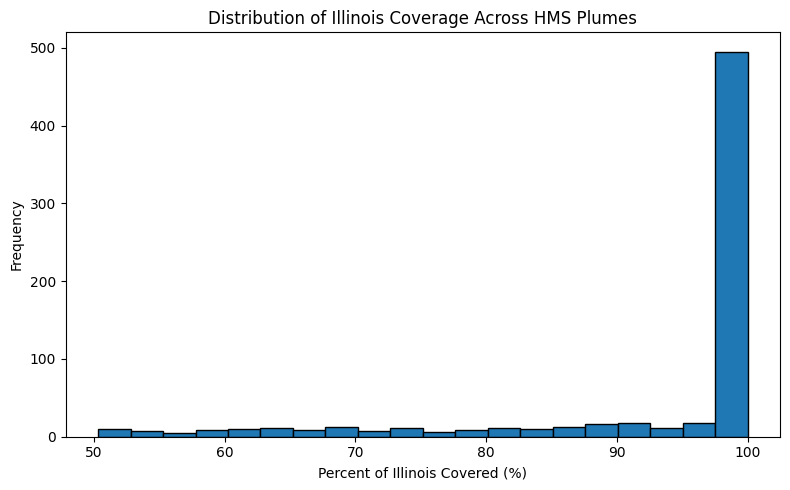

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(hms_50['pct_il_covered'].dropna(), bins=20, edgecolor='black')
plt.xlabel('Percent of Illinois Covered (%)')
plt.ylabel('Frequency')
plt.title('Distribution of Illinois Coverage Across HMS Plumes')
plt.tight_layout()
plt.show()

In [ ]:
# I want to save all unique "Smoke Aloft Dates"
smoke_aloft_days = (hms_50[["date_local"]].sort_values("date_local").reset_index(drop=True))
smoke_aloft_days.shape

(698, 1)

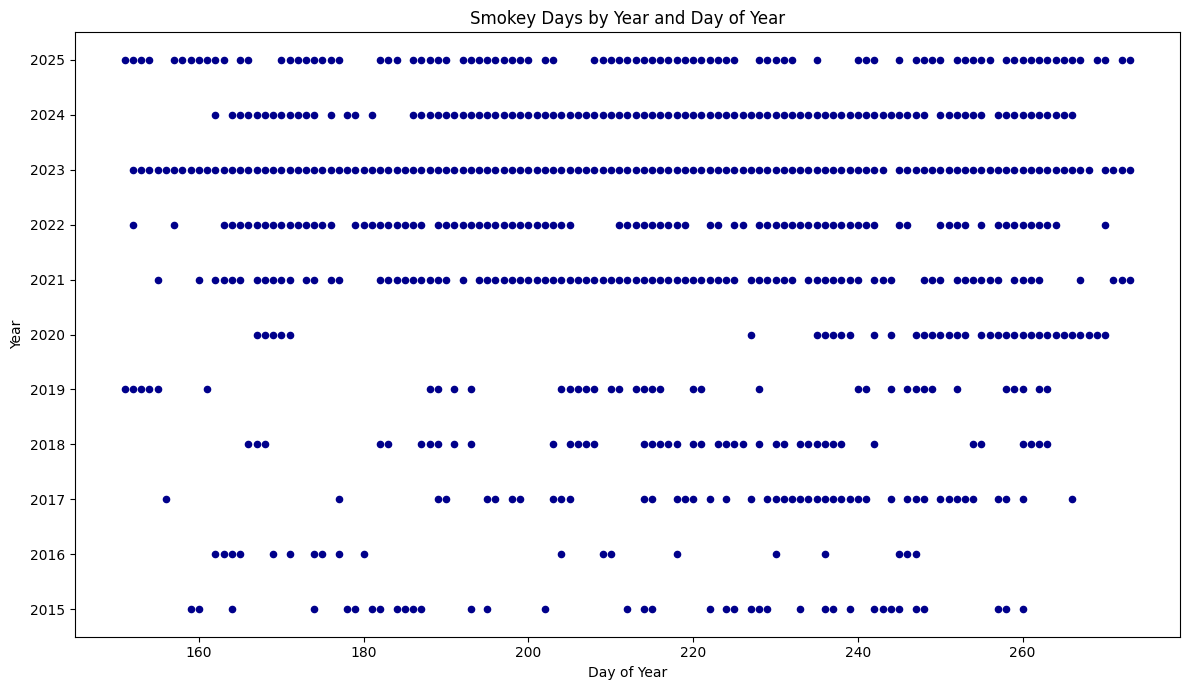

In [ ]:
## i want to visualize the days that qualified as "smokey"

# make dates in datetime format, and isolate day and year
smoke_aloft_days["date_local"] = pd.to_datetime(smoke_aloft_days["date_local"])
smoke_aloft_days["year"] = smoke_aloft_days["date_local"].dt.year
smoke_aloft_days["day_of_year"] = smoke_aloft_days["date_local"].dt.dayofyear

# and plot
fig, ax = plt.subplots(figsize=(12, 7))

ax.scatter(smoke_aloft_days["day_of_year"],smoke_aloft_days["year"],s=20, color="darkblue")

ax.set_xlabel("Day of Year")
ax.set_ylabel("Year")
ax.set_title("Smokey Days by Year and Day of Year")
ax.set_yticks(sorted(smoke_aloft_days["year"].unique()))

plt.tight_layout()
plt.show()

In [ ]:
## saving list to my drive
# smoke_aloft_days.to_csv('/content/drive/MyDrive/smoke_aloft_days.csv', index=False)

In [ ]:
## also saving cleaned geodataframe to my drive
# hms_50.to_file('/content/drive/MyDrive/ATMS596/hms_50.gpkg', driver="GPKG")

#Map of Smoke Polygons

In [ ]:
# for mapping purposes, I want to identify example dates where Illinois coverage is less than 100%
partial_coverage = hms_50[hms_50['pct_il_covered'] < 90]

# list dates and coverage percentages
partial_coverage[['date_local', 'pct_il_covered', 'Satellite']].sort_values('pct_il_covered')

,date_local,pct_il_covered,Satellite
138,2017-07-14,50.333830,GOES-WEST
219,2018-07-02,51.137351,GOES-EAST
87,2016-07-27,51.472147,GOES
437,2021-06-25,51.676400,GOES-EAST
341,2019-09-09,51.892751,GOES-WEST
...,...,...,...
606,2022-09-03,89.450739,GOES-EAST
410,2020-09-20,89.545410,GOES-EAST
921,2025-08-07,89.838893,GOES-WEST
47,2015-08-30,89.913825,GOES


In [ ]:
## For mapping, importing Illinois state boundaries.
states_url = "https://www2.census.gov/geo/tiger/GENZ2024/shp/cb_2024_us_state_500k.zip"
states = gpd.read_file(states_url)
illinois = states[states["STUSPS"] == "IL"].copy()

## Also importing Lake Michigan boundaries for mapping.
lakes_url = "https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_lakes.zip"
lakes = gpd.read_file(lakes_url)
lake_michigan = lakes[lakes["name"] == "Lake Michigan"].copy()


In [ ]:
## need to make sure we're on the same coordinate system
hms_50 = hms_50.to_crs(illinois.crs)
states = states.to_crs(illinois.crs)

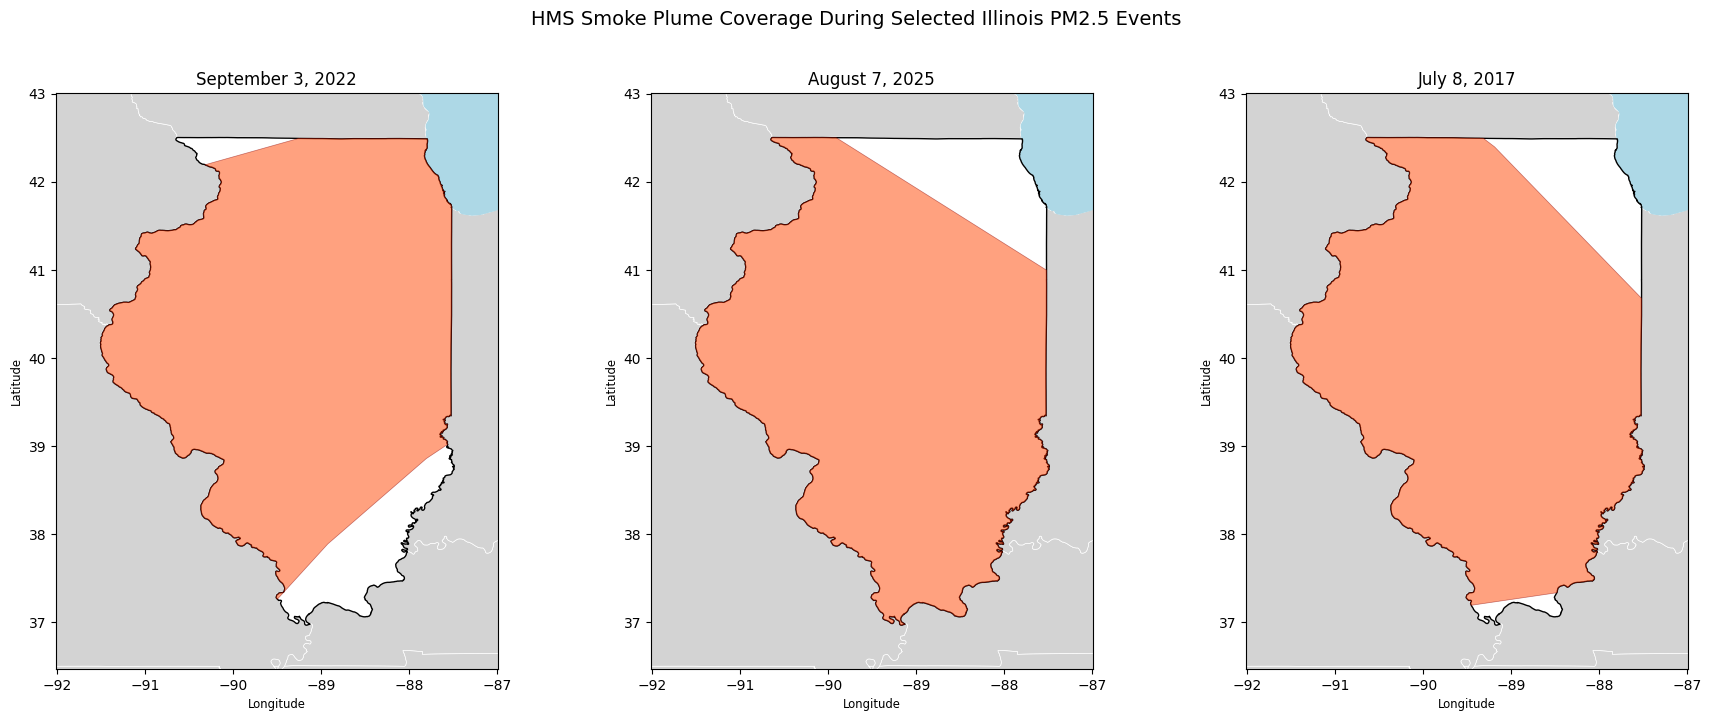

In [ ]:
# Define event dates, pulled a couple examples from list above
event_dates = ["2022-09-03", "2025-08-07", "2017-07-08"]

# Create figure with 3 panels
fig, axes = plt.subplots(1, 3, figsize=(18, 7))

# Get Illinois bounds for consistent map extent
minx, miny, maxx, maxy = illinois.total_bounds

for ax, event_date in zip(axes, event_dates):

    # Filter HMS polygons for the event date
    daily_smoke = hms_50[
        pd.to_datetime(hms_50["date_local"]).dt.strftime("%Y-%m-%d")
        == event_date
    ]

    # Plot all states in gray
    states.plot(ax=ax, facecolor="lightgray", edgecolor="white",
                linewidth=0.5)

    # Plot Lake Michigan
    lake_michigan.plot(ax=ax, facecolor="lightblue",
                       edgecolor="lightblue", zorder=1)

    # Plot Illinois on top in white
    illinois.plot(ax=ax, facecolor="white", edgecolor="black",
                  linewidth=1, zorder=2)

    # Plot HMS smoke polygons
    if not daily_smoke.empty:
        daily_smoke.plot(
            ax=ax,
            facecolor="orangered",
            edgecolor="darkred",
            linewidth=0.5,
            alpha=0.5,
            zorder=3
        )

    # Apply consistent map extent
    ax.set_xlim(minx - 0.5, maxx + 0.5)
    ax.set_ylim(miny - 0.5, maxy + 0.5)

    # Format panel
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title(pd.to_datetime(event_date).strftime("%B %-d, %Y"))

    # Keep map proportions consistent
    ax.set_aspect("equal")

plt.suptitle("HMS Smoke Plume Coverage During Selected Illinois PM2.5 Events",
             fontsize=14, y=1.02)

plt.tight_layout()
plt.show()